# EndoVis 2015 — Kaggle GPU U-Net Binary Segmentation

This notebook is designed for Kaggle Notebook with your prepared dataset.

Expected logical structure somewhere under `/kaggle/input/`:

```text
EndoVis2015_Binary_Segmentation/
├── metadata/
├── train/
│   ├── images/
│   └── masks/
├── val/
│   ├── images/
│   └── masks/
└── test/
    ├── images/
    └── masks/
```

## 1. Imports, seed and GPU check

In [1]:
from pathlib import Path
import gc, time, random, shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print("GPU:", gpu_name)
    print(f"GPU memory: {gpu_mem_gb:.2f} GB")
else:
    gpu_mem_gb = 0
    print("WARNING: GPU is not enabled.")
    print("Go to Kaggle Settings → Accelerator → GPU.")

PyTorch: 2.10.0+cu128
Device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB


## 2. Automatically locate the uploaded dataset

In [2]:
KAGGLE_INPUT = Path("/kaggle/input")

def find_dataset_root(search_root):
    candidates = []
    for p in search_root.rglob("*"):
        if not p.is_dir():
            continue
        required = [
            p / "train" / "images",
            p / "train" / "masks",
            p / "val" / "images",
            p / "val" / "masks",
            p / "test" / "images",
            p / "test" / "masks",
        ]
        if all(x.exists() for x in required):
            candidates.append(p)

    if not candidates:
        raise FileNotFoundError(
            "Could not find train/val/test image-mask folders under /kaggle/input."
        )

    preferred = [p for p in candidates if "endovis" in p.name.lower()]
    return preferred[0] if preferred else candidates[0]

DATA_ROOT = find_dataset_root(KAGGLE_INPUT)

print("Detected dataset root:")
print(DATA_ROOT)

print("\nContents:")
for p in sorted(DATA_ROOT.iterdir()):
    print(" -", p.name)

Detected dataset root:
/kaggle/input/datasets/tanvirhayat22mete013/endovis2015-binary-segmentation/EndoVis2015_Binary_Segmentation

Contents:
 - metadata
 - test
 - train
 - val


## 3. Configuration

In [3]:
INPUT_WIDTH = 320
INPUT_HEIGHT = 256

if DEVICE.type == "cuda":
    if gpu_mem_gb >= 14:
        BATCH_SIZE = 8
    elif gpu_mem_gb >= 8:
        BATCH_SIZE = 4
    else:
        BATCH_SIZE = 2
else:
    BATCH_SIZE = 1

NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
BASE_CHANNELS = 16

EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
THRESHOLD = 0.5
EARLY_STOPPING_PATIENCE = 7

WORK_DIR = Path("/kaggle/working/endovis_unet")
WORK_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = WORK_DIR / "best_unet.pth"
HISTORY_CSV = WORK_DIR / "training_history.csv"
TEST_METRICS_CSV = WORK_DIR / "test_metrics.csv"
PREDICTION_DIR = WORK_DIR / "test_predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("Input size (H, W):", (INPUT_HEIGHT, INPUT_WIDTH))
print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)
print("Base channels:", BASE_CHANNELS)
print("Epochs:", EPOCHS)

Input size (H, W): (256, 320)
Batch size: 8
Workers: 2
Base channels: 16
Epochs: 30


## 4. Verify image-mask pairing

In [4]:
def get_split_paths(split):
    image_dir = DATA_ROOT / split / "images"
    mask_dir = DATA_ROOT / split / "masks"

    image_paths = sorted(image_dir.glob("*.png"))
    mask_paths = sorted(mask_dir.glob("*.png"))

    if len(image_paths) == 0:
        raise RuntimeError(f"No PNG images found in {image_dir}")

    if len(image_paths) != len(mask_paths):
        raise RuntimeError(
            f"{split}: images={len(image_paths)}, masks={len(mask_paths)}"
        )

    if [p.name for p in image_paths] != [p.name for p in mask_paths]:
        raise RuntimeError(f"{split}: image and mask filenames do not match.")

    return image_paths, mask_paths

rows = []
for split in ["train", "val", "test"]:
    images, masks = get_split_paths(split)
    rows.append({"split": split, "images": len(images), "masks": len(masks)})

display(pd.DataFrame(rows))
print("Pairing check passed.")

,split,images,masks
0,train,2232,2232
1,val,1124,1124
2,test,1123,1123


Pairing check passed.


## 5. Dataset class

In [5]:
class EndoVisDataset(Dataset):
    def __init__(self, root, split, width=320, height=256, augment=False):
        self.root = Path(root)
        self.split = split
        self.width = width
        self.height = height
        self.augment = augment

        image_dir = self.root / split / "images"
        mask_dir = self.root / split / "masks"

        self.image_paths = sorted(image_dir.glob("*.png"))
        self.mask_paths = [mask_dir / p.name for p in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise RuntimeError(f"Could not read image: {image_path}")
        if mask is None:
            raise RuntimeError(f"Could not read mask: {mask_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.augment and random.random() < 0.5:
            image = cv2.flip(image, 1)
            mask = cv2.flip(mask, 1)

        image = cv2.resize(
            image,
            (self.width, self.height),
            interpolation=cv2.INTER_LINEAR,
        )

        mask = cv2.resize(
            mask,
            (self.width, self.height),
            interpolation=cv2.INTER_NEAREST,
        )

        image = image.astype(np.float32) / 255.0
        mask = (mask > 127).astype(np.float32)

        image = np.transpose(image, (2, 0, 1))
        mask = mask[None, :, :]

        return {
            "image": torch.from_numpy(np.ascontiguousarray(image)).float(),
            "mask": torch.from_numpy(np.ascontiguousarray(mask)).float(),
            "filename": image_path.name,
        }

## 6. Build datasets and inspect one sample

In [6]:
train_dataset = EndoVisDataset(
    DATA_ROOT, "train", INPUT_WIDTH, INPUT_HEIGHT, augment=True
)
val_dataset = EndoVisDataset(
    DATA_ROOT, "val", INPUT_WIDTH, INPUT_HEIGHT, augment=False
)
test_dataset = EndoVisDataset(
    DATA_ROOT, "test", INPUT_WIDTH, INPUT_HEIGHT, augment=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

sample = train_dataset[0]
print("Image tensor:", sample["image"].shape)
print("Mask tensor:", sample["mask"].shape)
print("Mask values:", torch.unique(sample["mask"]).tolist())

Train: 2232
Validation: 1124
Test: 1123
Image tensor: torch.Size([3, 256, 320])
Mask tensor: torch.Size([1, 256, 320])
Mask values: [0.0, 1.0]


## 7. Visualize one prepared sample

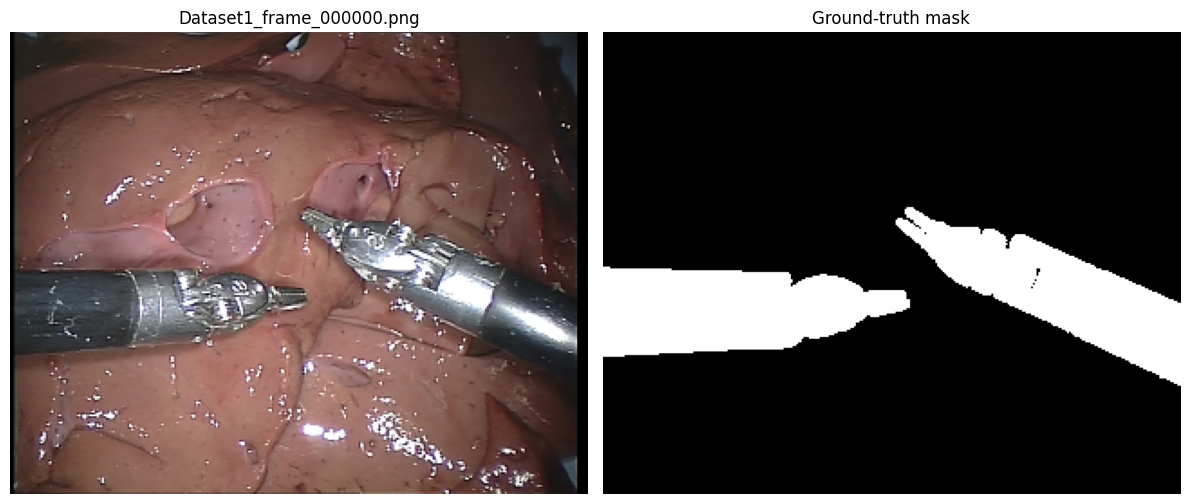

In [7]:
sample = train_dataset[0]
image = sample["image"].numpy().transpose(1, 2, 0)
mask = sample["mask"].numpy()[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title(sample["filename"])
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 8. DataLoaders

In [8]:
loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **loader_kwargs,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    **loader_kwargs,
)

batch = next(iter(train_loader))
print("Batch images:", batch["image"].shape)
print("Batch masks:", batch["mask"].shape)

del batch
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Batch images: torch.Size([8, 3, 256, 320])
Batch masks: torch.Size([8, 1, 256, 320])


## 9. Compact U-Net

In [9]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(in_channels, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.enc4 = DoubleConv(base * 4, base * 8)

        self.bottleneck = DoubleConv(base * 8, base * 16)

        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, 2, 2)
        self.dec4 = DoubleConv(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.dec3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec1 = DoubleConv(base * 2, base)

        self.out = nn.Conv2d(base, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)

## 10. Create model and GPU smoke test

In [10]:
model = UNet(
    in_channels=3,
    out_channels=1,
    base=BASE_CHANNELS,
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

x = torch.randn(1, 3, INPUT_HEIGHT, INPUT_WIDTH, device=DEVICE)

model.eval()
with torch.no_grad():
    y = model(x)

print("Input:", x.shape)
print("Output:", y.shape)

del x, y
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Total parameters: 1,942,577
Input: torch.Size([1, 3, 256, 320])
Output: torch.Size([1, 1, 256, 320])


## 11. BCE + Dice loss

In [11]:
bce_loss_fn = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)
    probs = probs.flatten(1)
    targets = targets.flatten(1)

    intersection = (probs * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probs.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1.0 - dice.mean()

def combined_loss(logits, targets):
    bce = bce_loss_fn(logits, targets)
    d = dice_loss(logits, targets)
    return bce + d, bce, d

## 12. Metrics

In [12]:
def confusion_counts_from_logits(logits, targets, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = probs >= threshold
    targets_bool = targets >= 0.5

    tp = torch.logical_and(preds, targets_bool).sum().item()
    fp = torch.logical_and(preds, ~targets_bool).sum().item()
    fn = torch.logical_and(~preds, targets_bool).sum().item()

    return tp, fp, fn

def metrics_from_counts(tp, fp, fn, eps=1e-7):
    return {
        "dice": (2 * tp + eps) / (2 * tp + fp + fn + eps),
        "iou": (tp + eps) / (tp + fp + fn + eps),
        "precision": (tp + eps) / (tp + fp + eps),
        "recall": (tp + eps) / (tp + fn + eps),
    }

## 13. Optimizer, scheduler and mixed precision

In [13]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP,
)

print("AMP enabled:", USE_AMP)

AMP enabled: True


## 14. Train/evaluate functions

In [14]:
def train_one_epoch(model, loader):
    model.train()

    total_loss = total_bce = total_dice_loss = 0.0
    total_tp = total_fp = total_fn = 0

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(images)
            loss, bce, dloss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tp, fp, fn = confusion_counts_from_logits(
            logits.detach(), masks, THRESHOLD
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

        total_loss += loss.item() * images.size(0)
        total_bce += bce.item() * images.size(0)
        total_dice_loss += dloss.item() * images.size(0)

    n = len(loader.dataset)

    return {
        "loss": total_loss / n,
        "bce_loss": total_bce / n,
        "dice_loss": total_dice_loss / n,
        **metrics_from_counts(total_tp, total_fp, total_fn),
    }


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = total_bce = total_dice_loss = 0.0
    total_tp = total_fp = total_fn = 0

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(images)
            loss, bce, dloss = combined_loss(logits, masks)

        tp, fp, fn = confusion_counts_from_logits(
            logits, masks, THRESHOLD
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

        total_loss += loss.item() * images.size(0)
        total_bce += bce.item() * images.size(0)
        total_dice_loss += dloss.item() * images.size(0)

    n = len(loader.dataset)

    return {
        "loss": total_loss / n,
        "bce_loss": total_bce / n,
        "dice_loss": total_dice_loss / n,
        **metrics_from_counts(total_tp, total_fp, total_fn),
    }

## 15. Train U-Net

In [ ]:
history = []
best_val_dice = -1.0
epochs_without_improvement = 0

training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = train_one_epoch(model, train_loader)
    val_metrics = evaluate(model, val_loader)

    scheduler.step(val_metrics["dice"])
    lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "lr": lr,
        "train_loss": train_metrics["loss"],
        "train_dice": train_metrics["dice"],
        "train_iou": train_metrics["iou"],
        "val_loss": val_metrics["loss"],
        "val_dice": val_metrics["dice"],
        "val_iou": val_metrics["iou"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
    }

    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    epoch_minutes = (time.time() - epoch_start) / 60

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"{epoch_minutes:.2f} min | "
        f"Train Loss {train_metrics['loss']:.4f} | "
        f"Train Dice {train_metrics['dice']:.4f} | "
        f"Val Loss {val_metrics['loss']:.4f} | "
        f"Val Dice {val_metrics['dice']:.4f} | "
        f"Val IoU {val_metrics['iou']:.4f} | "
        f"LR {lr:.2e}"
    )

    if val_metrics["dice"] > best_val_dice:
        best_val_dice = val_metrics["dice"]
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_val_dice": best_val_dice,
                "input_width": INPUT_WIDTH,
                "input_height": INPUT_HEIGHT,
                "base_channels": BASE_CHANNELS,
                "threshold": THRESHOLD,
            },
            BEST_MODEL_PATH,
        )

        print(f"  Saved best model: Val Dice = {best_val_dice:.4f}")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\nTraining time: {(time.time() - training_start)/60:.2f} minutes")
history_df = pd.DataFrame(history)
display(history_df.tail())

Epoch 01/30 | 1.38 min | Train Loss 0.6454 | Train Dice 0.9136 | Val Loss 0.4456 | Val Dice 0.8369 | Val IoU 0.7196 | LR 1.00e-03
  Saved best model: Val Dice = 0.8369
Epoch 02/30 | 0.59 min | Train Loss 0.1848 | Train Dice 0.9435 | Val Loss 0.5449 | Val Dice 0.6704 | Val IoU 0.5042 | LR 1.00e-03
Epoch 03/30 | 0.55 min | Train Loss 0.1223 | Train Dice 0.9473 | Val Loss 0.5676 | Val Dice 0.6582 | Val IoU 0.4905 | LR 1.00e-03
Epoch 04/30 | 0.54 min | Train Loss 0.1090 | Train Dice 0.9491 | Val Loss 0.4880 | Val Dice 0.7733 | Val IoU 0.6304 | LR 1.00e-03
Epoch 05/30 | 0.55 min | Train Loss 0.1013 | Train Dice 0.9515 | Val Loss 0.2607 | Val Dice 0.8401 | Val IoU 0.7243 | LR 1.00e-03
  Saved best model: Val Dice = 0.8401
Epoch 06/30 | 0.55 min | Train Loss 0.1072 | Train Dice 0.9475 | Val Loss 0.2402 | Val Dice 0.8495 | Val IoU 0.7383 | LR 1.00e-03
  Saved best model: Val Dice = 0.8495
Epoch 07/30 | 0.55 min | Train Loss 0.1005 | Train Dice 0.9504 | Val Loss 0.2949 | Val Dice 0.8324 | Val I

## 16. Training curves

In [ ]:
history_df = pd.read_csv(HISTORY_CSV)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_dice"], label="Train")
plt.plot(history_df["epoch"], history_df["val_dice"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Dice Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_iou"], label="Train")
plt.plot(history_df["epoch"], history_df["val_iou"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("IoU")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 17. Load best model and test

In [ ]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["best_val_dice"])

test_metrics = evaluate(model, test_loader)
test_df = pd.DataFrame([test_metrics])

display(test_df)

test_df.to_csv(TEST_METRICS_CSV, index=False)
print("Saved:", TEST_METRICS_CSV)

## 18. Visualize test predictions

In [ ]:
@torch.no_grad()
def show_prediction(dataset, idx):
    model.eval()

    sample = dataset[idx]
    image_tensor = sample["image"].unsqueeze(0).to(DEVICE)

    with torch.amp.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=USE_AMP,
    ):
        logits = model(image_tensor)

    probability = torch.sigmoid(logits)[0, 0].float().cpu().numpy()
    prediction = (probability >= THRESHOLD).astype(np.uint8)

    image = sample["image"].numpy().transpose(1, 2, 0)
    gt = sample["mask"].numpy()[0]

    overlay = image.copy()
    overlay[..., 1] = np.maximum(
        overlay[..., 1],
        prediction * 0.75,
    )

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    axes[0].imshow(image)
    axes[0].set_title(sample["filename"])

    axes[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground Truth")

    axes[2].imshow(probability, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Probability")

    axes[3].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[3].set_title("Prediction")

    axes[4].imshow(overlay)
    axes[4].set_title("Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

for idx in [0, 100, 300, 600, 900]:
    if idx < len(test_dataset):
        show_prediction(test_dataset, idx)

## 19. Save all predicted test masks

In [ ]:
@torch.no_grad()
def save_predictions(model, loader, output_dir):
    model.eval()
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    total = 0

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP,
        ):
            logits = model(images)

        probs = torch.sigmoid(logits)
        preds = (probs >= THRESHOLD).to(torch.uint8) * 255
        preds = preds.cpu().numpy()

        for i, filename in enumerate(batch["filename"]):
            cv2.imwrite(
                str(output_dir / filename),
                preds[i, 0],
            )
            total += 1

    return total

saved = save_predictions(model, test_loader, PREDICTION_DIR)

print("Saved masks:", saved)
print(PREDICTION_DIR)

## 20. Zip Kaggle outputs

In [ ]:
archive_path = shutil.make_archive(
    "/kaggle/working/endovis_unet_results",
    "zip",
    root_dir=WORK_DIR,
)

print("Created:", archive_path)
print("Best model:", BEST_MODEL_PATH)
print("History:", HISTORY_CSV)
print("Test metrics:", TEST_METRICS_CSV)
print("Predictions:", PREDICTION_DIR)